The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Size of dataset: 7

Size of dataset: 7



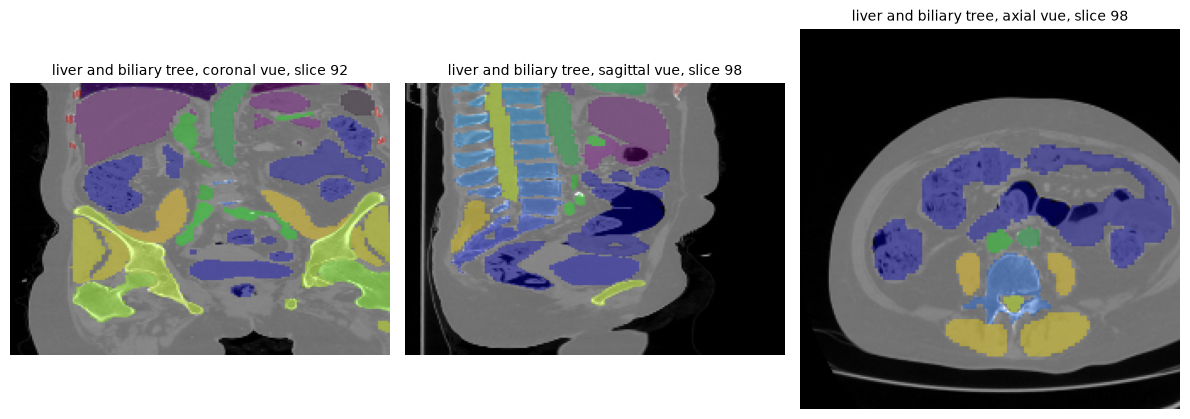

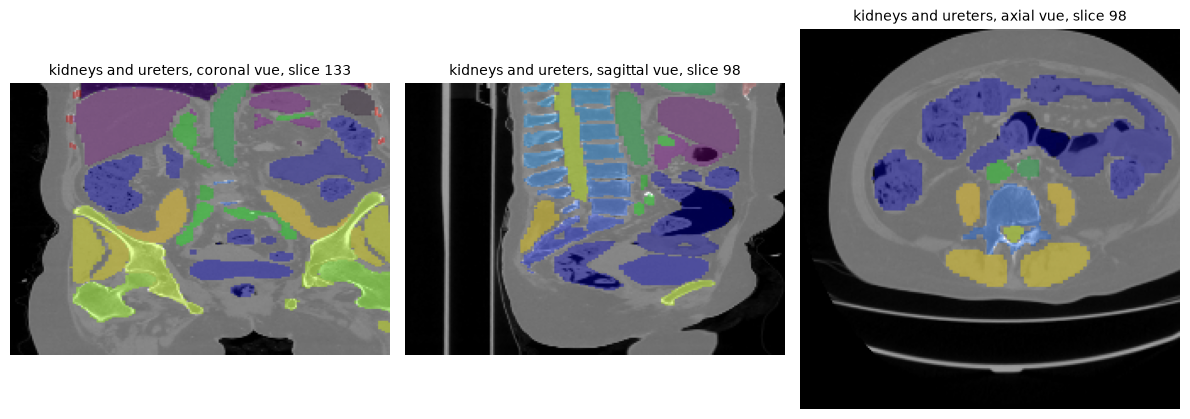

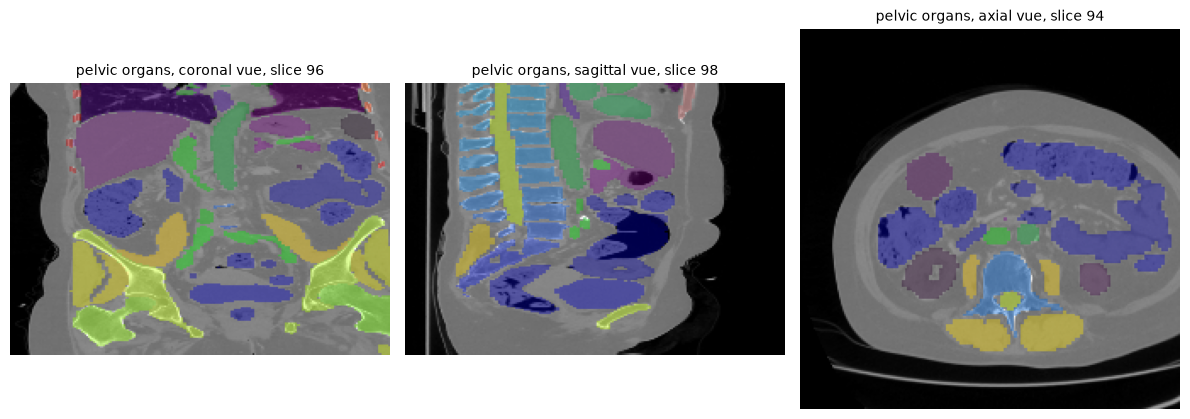

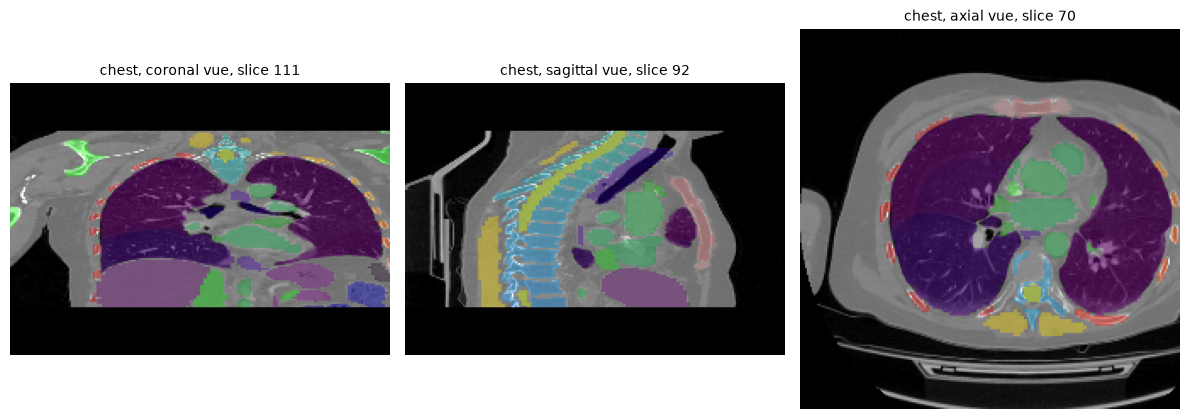

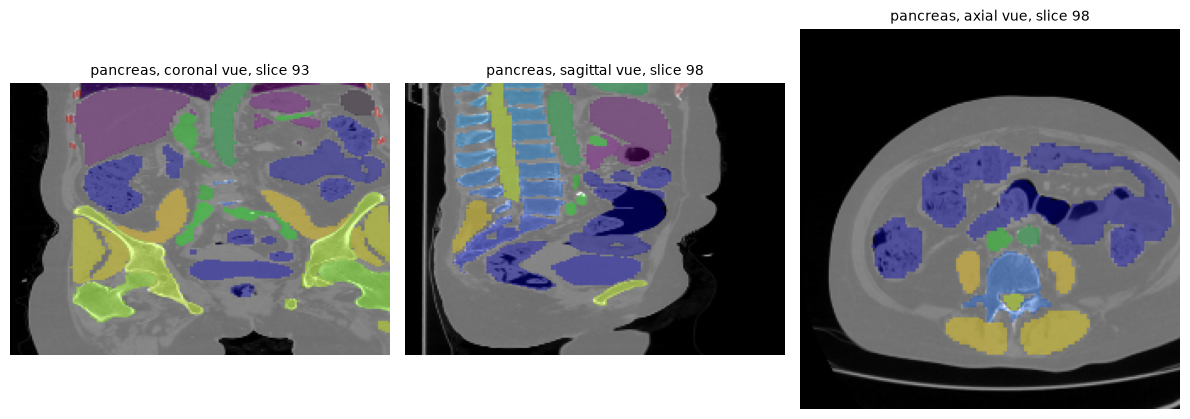

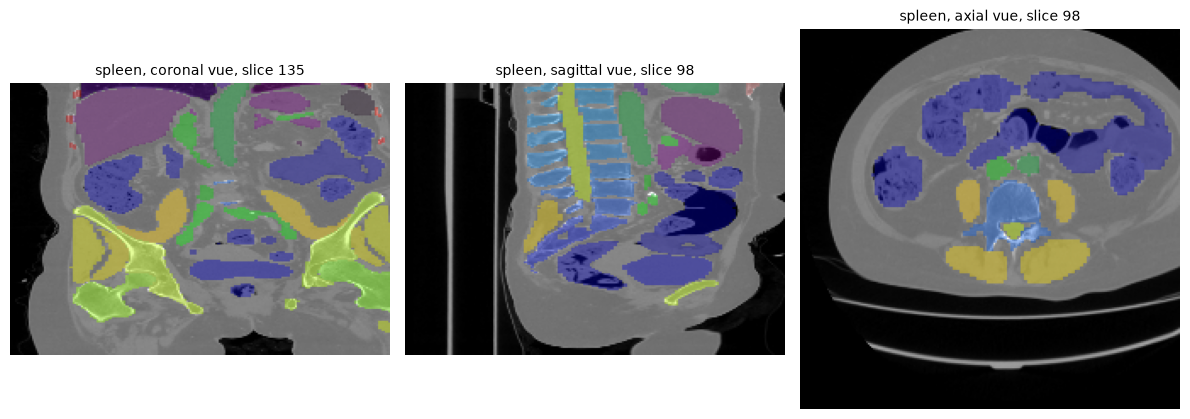

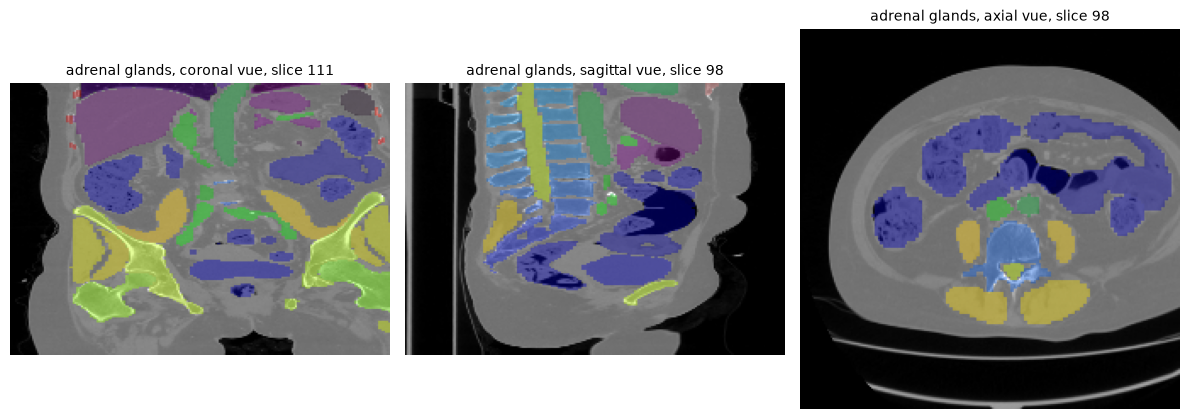

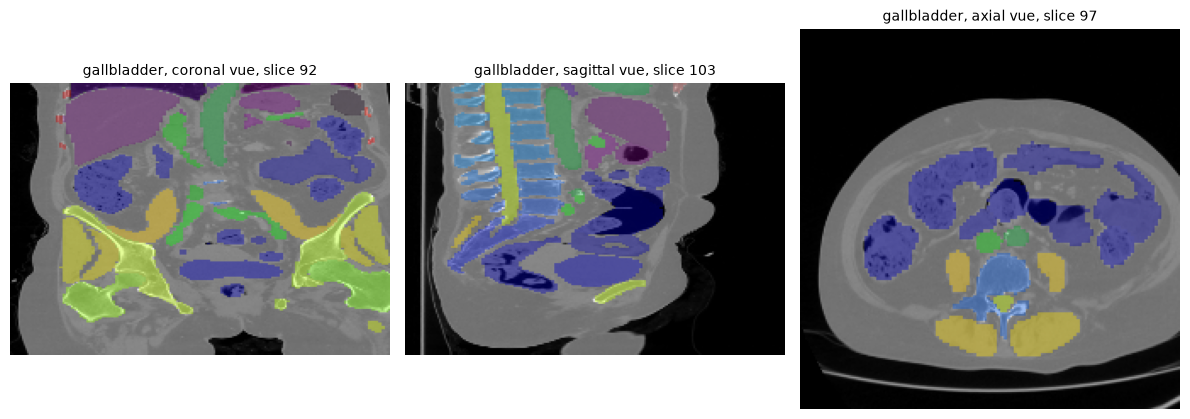

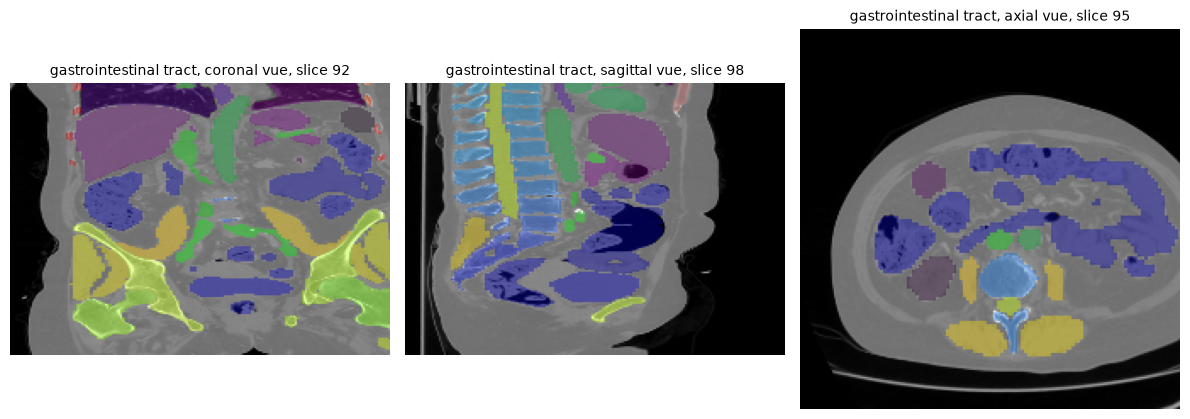

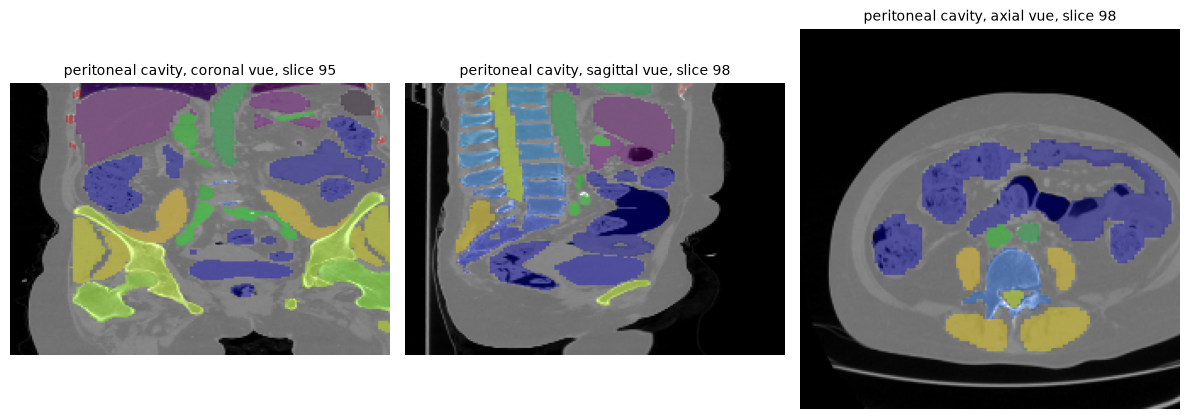

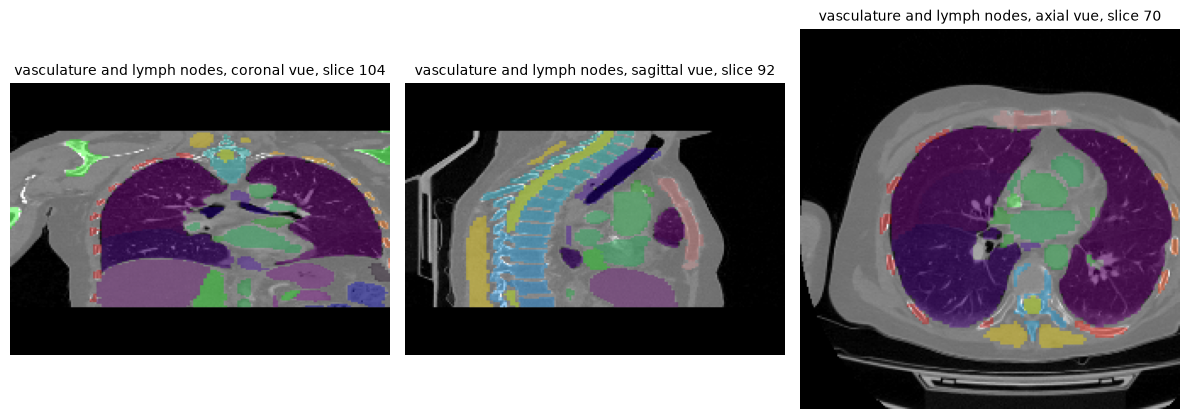

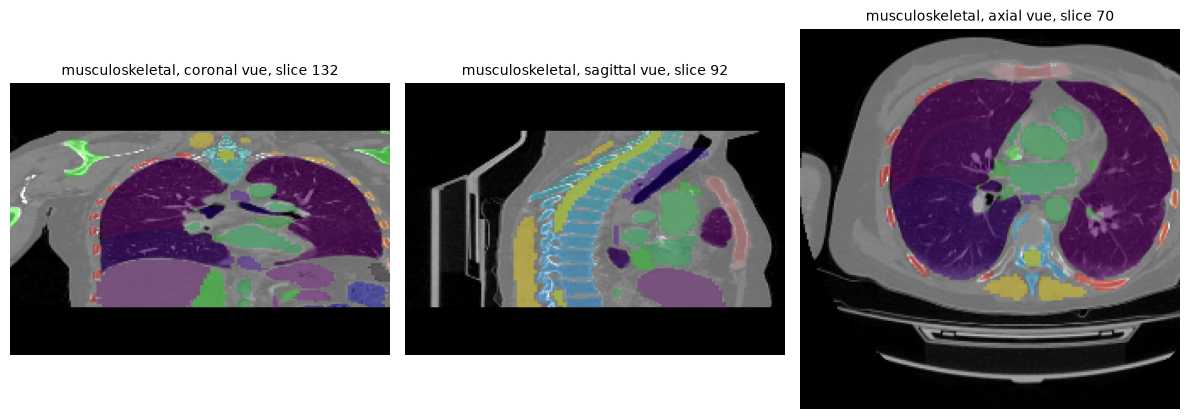

In [ ]:
%load_ext autoreload
%autoreload 2

import torch
import matplotlib.pyplot as plt
import matplotlib as mpl
import os
import numpy as np
import pickle
from matplotlib.colors import ListedColormap
from captor.data.dataloaders import DataLoader
from captor.data.monai_transforms import SegmentationTransforms

images_dir = './data' 
segmentations_dir = './segmentations' 
path_dict_std_to_region_to_series_reports = './dict_std_to_region_to_series_reports.pkl' 
path_global_dict_crop_centers = "./global_dict_crop_centers.pkl"
cache_dir = './cache'
cache_dir_seg = './cache_seg'
global_dict_crop_centers = pickle.load(open(path_global_dict_crop_centers, "rb"))
dict_std_to_region_to_series_reports = pickle.load(open(path_dict_std_to_region_to_series_reports, "rb"))

num_organs = 120
vivid_map = mpl.colormaps["nipy_spectral"]
fixed_cmap = ListedColormap(vivid_map(np.linspace(0,1,num_organs)))

regions = [
'liver and biliary tree',
'kidneys and ureters',
'pelvic organs',
'chest',
'pancreas',
'spleen',
'adrenal glands',
'gallbladder',
'gastrointestinal tract',
'peritoneal cavity',
'vasculature and lymph nodes',
'musculoskeletal']


studies = [study for study, val in dict_std_to_region_to_series_reports.items()]
datalist = [{
            "image": dict_std_to_region_to_series_reports[study]['series'],
            "text" : dict_std_to_region_to_series_reports[study]['report'],
            "series_names" : dict_std_to_region_to_series_reports[study]['series'],
            } for study in studies]

dataloader = DataLoader(
    datalist = datalist,
    images_dir = images_dir,
    cache_dir = cache_dir,
    batchsize = 1,
    global_dict_crop_centers = global_dict_crop_centers,
    shuffle = False,
    num_workers = 0,
    force_write_cache = False)

seg_dataloader = DataLoader(
    datalist = datalist,
    images_dir = segmentations_dir,
    cache_dir = cache_dir_seg,
    batchsize = 1,
    global_dict_crop_centers = global_dict_crop_centers,
    shuffle = False,
    num_workers = 0,
    force_write_cache = False,
    extension='.nii',
    transform_image=SegmentationTransforms)

dataset = dataloader.dataset
seg_dataset = seg_dataloader.dataset

index_pat = 0
for region in regions :

    dataset.set_region(region)
    seg_dataset.set_region(region)
    # series_name = dataset[index_pat]['series_name'][region]
    # Charger le fichier avec précaution
    try:
        image_volume = dataset[index_pat]['image'].squeeze(0)
        segmentation_volume = seg_dataset[index_pat]['image'].squeeze(0)
    except Exception as e:
        print("Erreur during load :", e)
        exit()


    non_zero_indices = torch.nonzero(segmentation_volume)

    # non_zero_indices = []
    if len(non_zero_indices) == 0 :
        center = [image_volume.shape[i]//2 for i in range(3)]
    else:
        center = non_zero_indices.float().mean(dim=0).long()

    # Sélection d'une slice
    # 'axial'
    slice_index_axial = center[1]
    image_slice_axial = image_volume[:, slice_index_axial, :].permute(1,0).flip(0).flip(1)
    segmentation_slice_axial = segmentation_volume[:, slice_index_axial, :].permute(1,0).flip(0).flip(1)

    # 'sagittal'
    slice_index_coronal = center[0]
    image_slice_coronal = image_volume[slice_index_coronal, :, :].permute(1,0).flip(0)
    segmentation_slice_coronal = segmentation_volume[slice_index_coronal, :, :].permute(1,0).flip(0)


    # 'sagittal'
    slice_index_sagittal = center[2]
    # slice_index_sagittal = 125
    image_slice_sagittal = image_volume[:,:,slice_index_sagittal].permute(1,0).flip(0).flip(1)
    segmentation_slice_sagittal = segmentation_volume[:,:,slice_index_sagittal].permute(1,0).flip(0).flip(1)

    # Affichage
    fig, axes = plt.subplots(1, 3, figsize=(12, 6))
    vue = 'coronal'
    seg_axial = segmentation_slice_axial.cpu().detach().numpy().astype(np.uint8)
    seg_axial_masked = np.ma.masked_where(seg_axial==0, seg_axial)

    axes[0].imshow(image_slice_axial.cpu().detach().numpy(), cmap='gray')
    axes[0].imshow(seg_axial_masked, cmap=fixed_cmap, alpha=0.4, vmin=0, vmax=num_organs-1) #'nipy_spectral'
    axes[0].set_title(f"{region}, {vue} vue, slice {slice_index_axial}", fontsize=10)
    axes[0].axis('off')

    vue = 'sagittal'
    seg_coronal = segmentation_slice_coronal.cpu().detach().numpy().astype(np.uint8)
    seg_coronal_masked = np.ma.masked_where(seg_coronal==0, seg_coronal)

    axes[1].imshow(image_slice_coronal.cpu().detach().numpy(), cmap='gray')
    axes[1].imshow(seg_coronal_masked, cmap=fixed_cmap, alpha=0.4,vmin=0, vmax=num_organs-1)
    axes[1].set_title(f"{region}, {vue} vue, slice {slice_index_coronal}", fontsize=10)
    axes[1].axis('off')

    vue = 'axial'
    seg_sagittal = segmentation_slice_sagittal.cpu().detach().numpy().astype(np.uint8)
    seg_sagittal_masked = np.ma.masked_where(seg_sagittal==0, seg_sagittal)

    axes[2].imshow(image_slice_sagittal.cpu().detach().numpy(), cmap='gray')
    axes[2].imshow(seg_sagittal_masked, cmap=fixed_cmap, alpha=0.4,vmin=0, vmax=num_organs-1)
    axes[2].set_title(f"{region}, {vue} vue, slice {slice_index_sagittal}", fontsize=10)
    axes[2].axis('off')
    plt.tight_layout()
    plt.show()


    # fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    # axes[0].imshow(image_slice_axial.cpu().detach().numpy(), cmap='gray')
    # axes[0].set_title(f"Image Slice {slice_index_axial}")
    # axes[0].axis('off')

    # axes[1].imshow(segmentation_slice_axial.cpu().detach().numpy(), cmap='nipy_spectral')
    # axes[1].set_title(f"Segmentation Slice {slice_index_axial}")
    # axes[1].axis('off')

    # plt.tight_layout()
    # plt.show()

